In [54]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn)
import warnings
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42   

In [55]:
data = pd.read_csv('/Users/elyne/Desktop/AI Journey/ITS/ML/FP-MachineLearning/Dataset/Paddy/paddydataset.csv')
data

      Hectares      Agriblock      Variety Soil Types  Seedrate(in Kg)  \
0             6     Cuddalore        CO_43   alluvial              150   
1             6   Kurinjipadi      ponmani       clay              150   
2             6       Panruti  delux ponni   alluvial              150   
3             6  Kallakurichi        CO_43       clay              150   
4             6  Sankarapuram      ponmani   alluvial              150   
...         ...           ...          ...        ...              ...   
2784          1  Kallakurichi        CO_43   alluvial               25   
2785          1  Sankarapuram      ponmani       clay               25   
2786          1   Chinnasalem  delux ponni       clay               25   
2787          1     Cuddalore        CO_43   alluvial               25   
2788          1   Kurinjipadi  delux ponni       clay               25   

      LP_Mainfield(in Tonnes) Nursery  Nursery area (Cents)  \
0                        75.0     dry           

## EDA 

In [56]:
print(data.shape)
data.info()

(2789, 45)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   object 
 2   Variety                             2789 non-null   object 
 3   Soil Types                          2789 non-null   object 
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   object 
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                     

In [57]:
print('Missing value :', data.isna().sum().sum())
print('Duplikat      :', data.duplicated().sum())

Missing value : 0
Duplikat      : 451


In [58]:
data.describe().T

                                     count          mean          std  \
Hectares                            2789.0      3.717461     1.437777   
Seedrate(in Kg)                     2789.0     92.936536    35.944420   
LP_Mainfield(in Tonnes)             2789.0     46.468268    17.972210   
Nursery area (Cents)                2789.0     74.349229    28.755536   
LP_nurseryarea(in Tonnes)           2789.0      3.717461     1.437777   
DAP_20days                          2789.0    148.698458    57.511072   
Weed28D_thiobencarb                 2789.0      7.434923     2.875554   
Urea_40Days                         2789.0    100.854729    39.006885   
Potassh_50Days                      2789.0     38.587250    14.924123   
Micronutrients_70Days               2789.0     55.761922    21.566652   
Pest_60Day(in ml)                   2789.0   2230.476873   862.666087   
30DRain( in mm)                     2789.0     18.723593     0.643789   
30DAI(in mm)                        2789.0     21.2

In [59]:
data.describe(include='object').T

                        count unique           top  freq
Agriblock                2789      6  Sankarapuram   605
Variety                  2789      3       ponmani  1061
Soil Types               2789      2          clay  1521
Nursery                  2789      2           dry  1540
Wind Direction_D1_D30    2789      6           SSE   605
Wind Direction_D31_D60   2789      5             W  1055
Wind Direction_D61_D90   2789      5            SE   899
Wind Direction_D91_D120  2789      6            NW   605

In [60]:
target = 'Paddy yield(in Kg)'
y = data[target]
pd.DataFrame({
    'Min': [y.min()], 'Max': [y.max()], 'Range': [y.max() - y.min()],
    'Mean': [y.mean()], 'Median': [y.median()], 'Std': [y.std()],
    'Skewness': [y.skew()], 'Kurtosis': [y.kurt()]
}, index=[target]).T.round(3)

          Paddy yield(in Kg)
Min                 5410.000
Max                38814.000
Range              33404.000
Mean               22517.729
Median             24636.000
Std                 9199.661
Skewness              -0.322
Kurtosis              -1.071

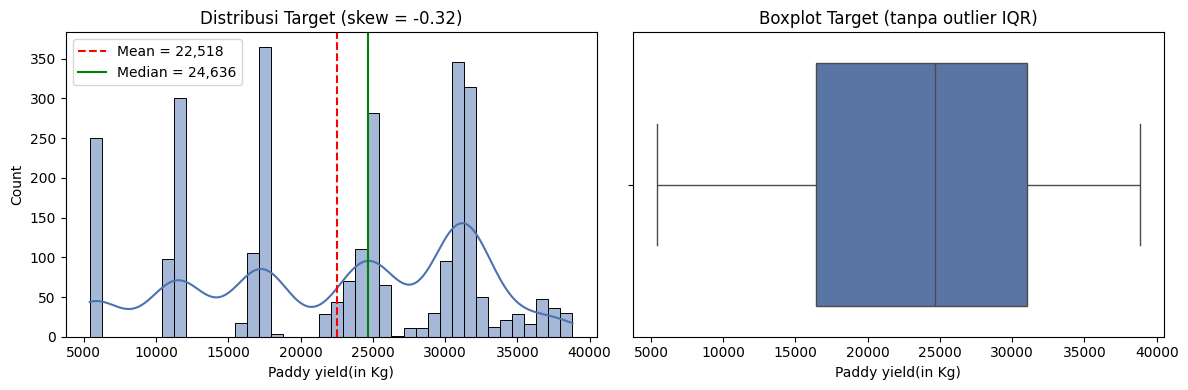

In [61]:
target = 'Paddy yield(in Kg)'
y = data[target]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(y, bins=40, kde=True, ax=ax[0], color='#4C72B0')
ax[0].axvline(y.mean(), color='red', ls='--', label=f'Mean = {y.mean():,.0f}')
ax[0].axvline(y.median(), color='green', ls='-', label=f'Median = {y.median():,.0f}')
ax[0].set_title(f'Distribusi Target (skew = {y.skew():.2f})'); ax[0].legend()

sns.boxplot(x=y, ax=ax[1], color='#4C72B0')
ax[1].set_title('Boxplot Target (tanpa outlier IQR)')

plt.tight_layout()
plt.savefig('target_distribution.png', dpi=200)  # buat dimasukin ke slide
plt.show()

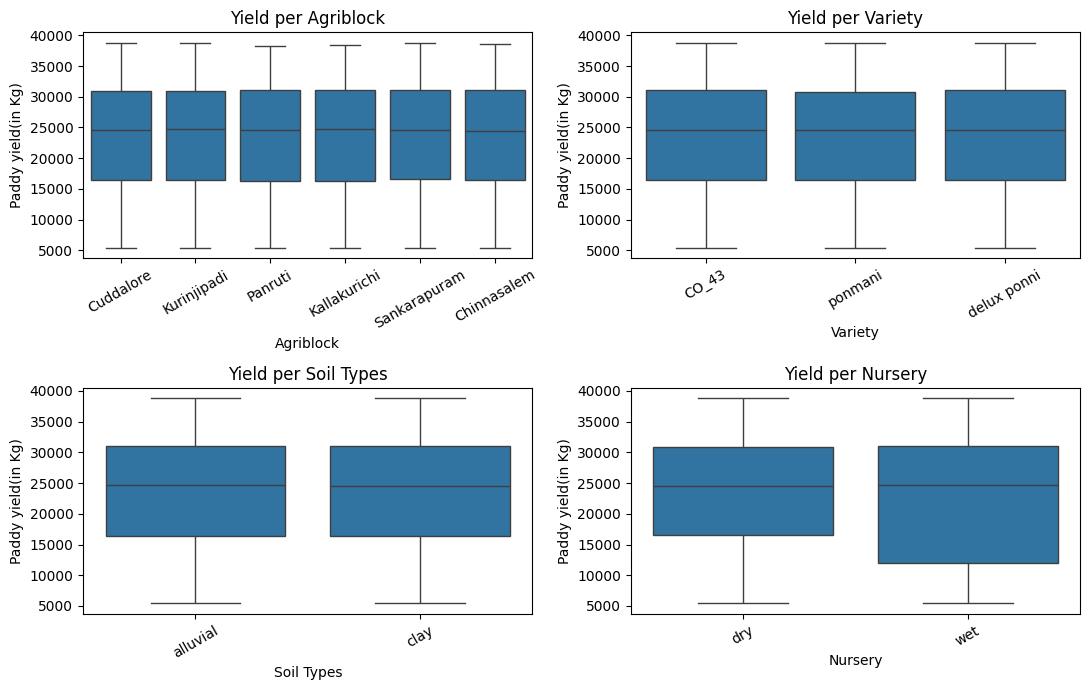

In [62]:
cat_cols = ['Agriblock', 'Variety', 'Soil Types', 'Nursery']
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), cat_cols):
    sns.boxplot(data=data, x=c, y=target, ax=a)
    a.set_title(f'Yield per {c}'); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

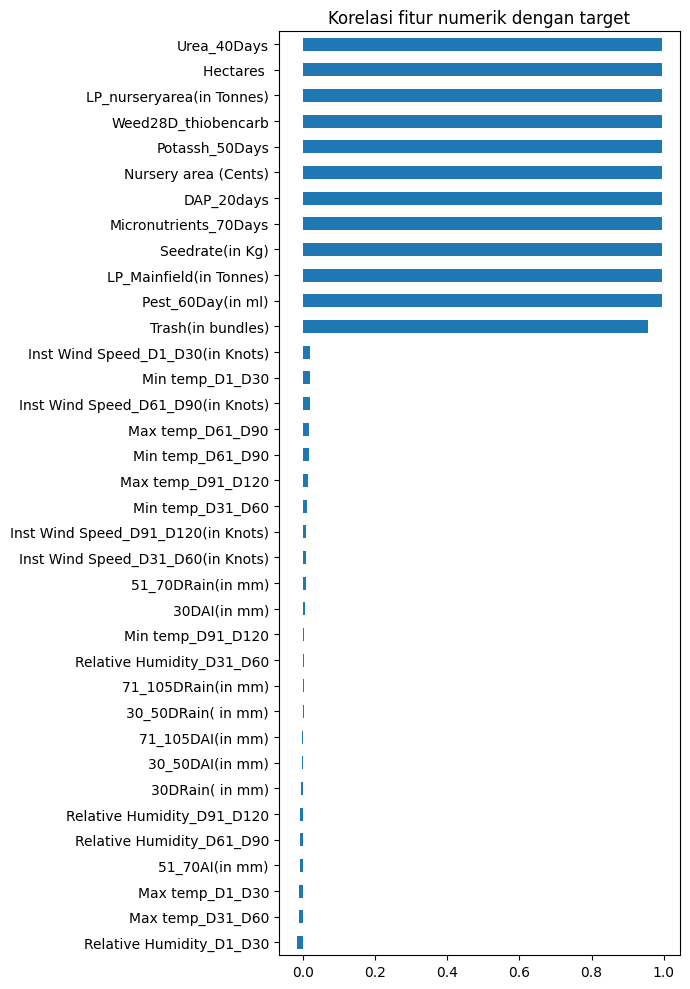

In [63]:
corr = data.select_dtypes('number').corr()[target].drop(target).sort_values()
plt.figure(figsize=(7, 10))
corr.plot.barh()
plt.title('Korelasi fitur numerik dengan target')
plt.tight_layout(); plt.show()

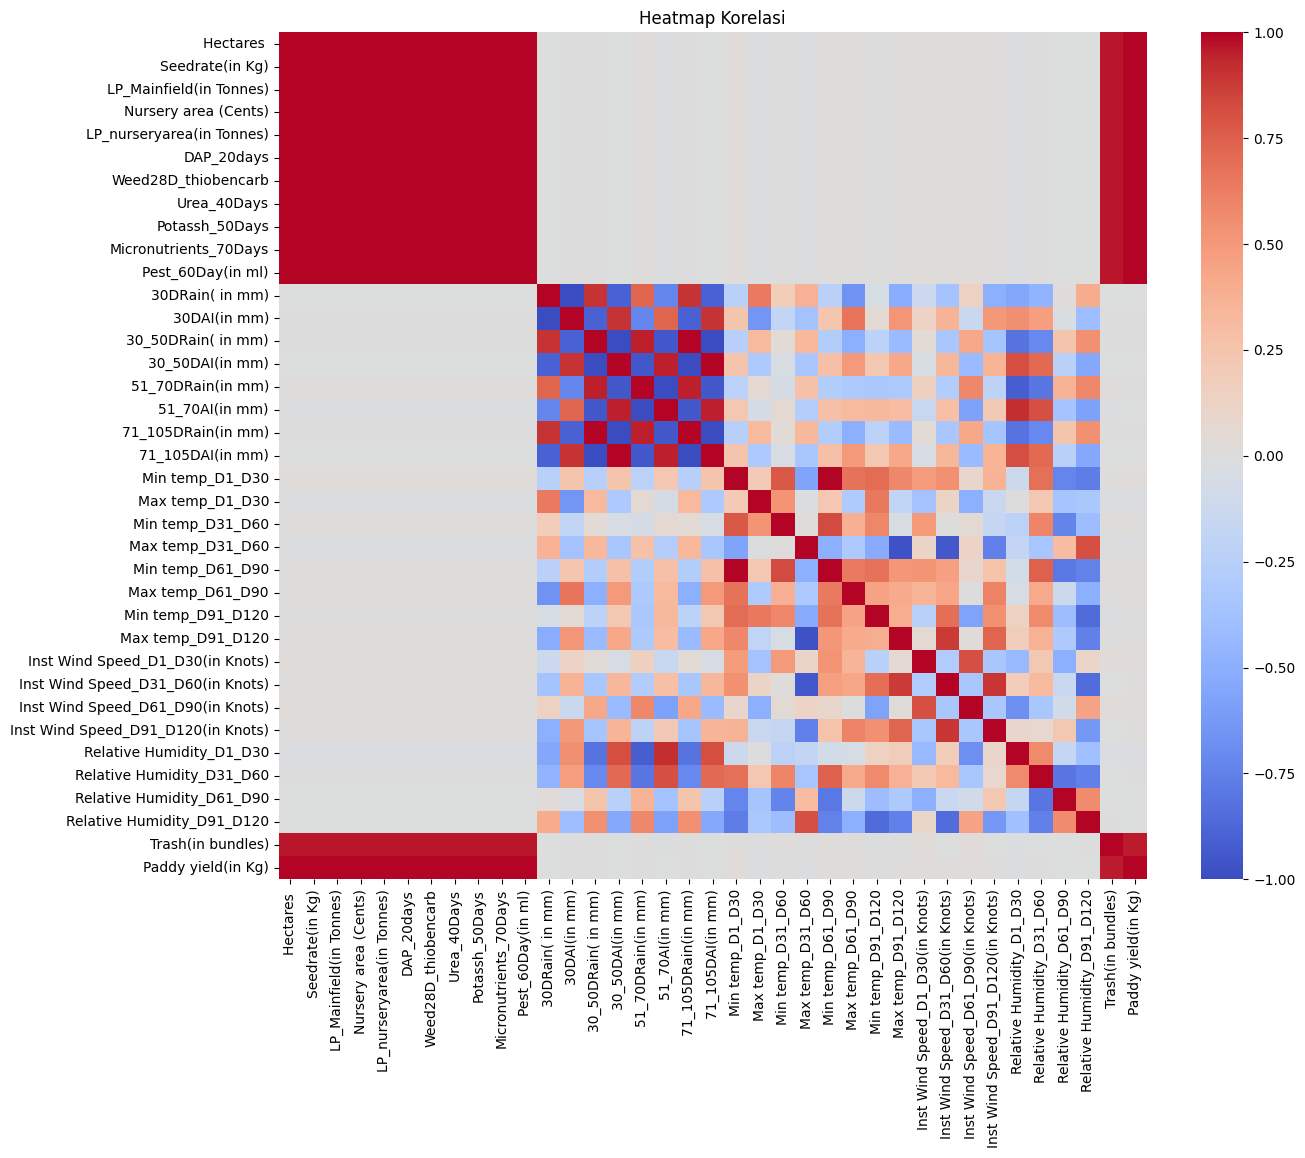

In [64]:
num = data.select_dtypes('number')
plt.figure(figsize=(14, 11))
sns.heatmap(num.corr(), cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi'); plt.show()

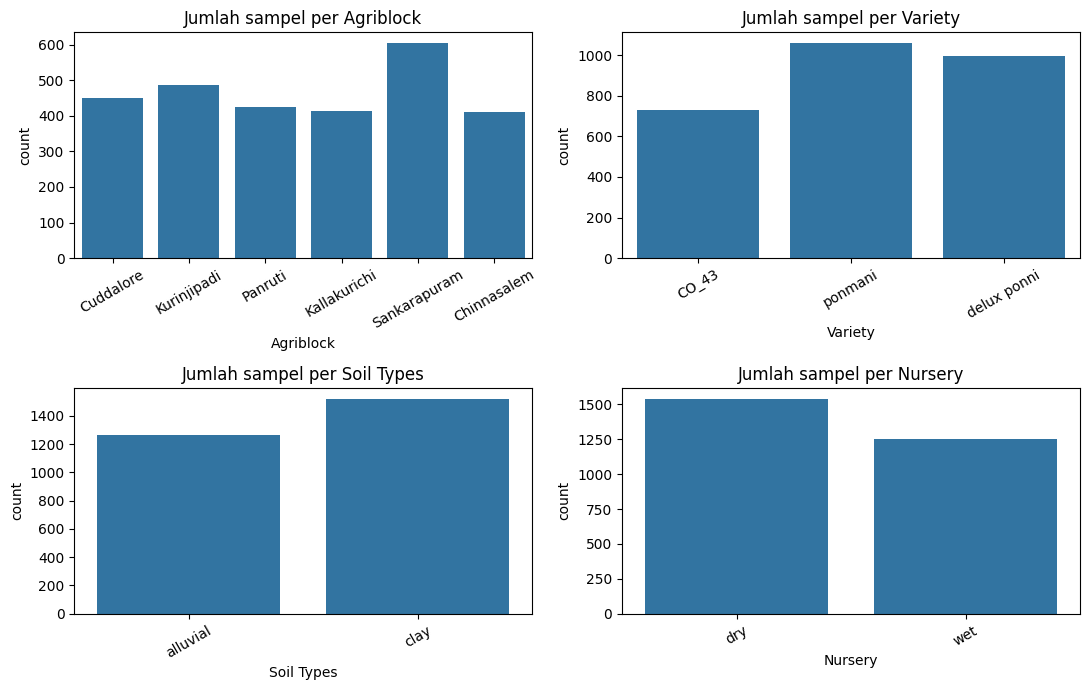

{'Sankarapuram': 0.217, 'Kurinjipadi': 0.174, 'Cuddalore': 0.161, 'Panruti': 0.152, 'Kallakurichi': 0.148, 'Chinnasalem': 0.147}
{'ponmani': 0.38, 'delux ponni': 0.357, 'CO_43': 0.262}
{'clay': 0.545, 'alluvial': 0.455}
{'dry': 0.552, 'wet': 0.448}


In [65]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), cat_cols):
    sns.countplot(data=data, x=c, ax=a)
    a.set_title(f'Jumlah sampel per {c}'); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
for c in cat_cols:
    print(data[c].value_counts(normalize=True).round(3).to_dict())

In [66]:
# Jumlah nilai unik per kolom (melihat fitur diskrit / hampir konstan)
data.nunique().sort_values().to_frame('n_unique').T

          Soil Types  Nursery  71_105DAI(in mm)  71_105DRain(in mm)  \
n_unique           2        2                 3                   3   

          51_70AI(in mm)  51_70DRain(in mm)  30_50DAI(in mm)  \
n_unique               3                  3                3   

          30_50DRain( in mm)  30DAI(in mm)  30DRain( in mm)  ...  \
n_unique                   3             3                3  ...   

          Weed28D_thiobencarb  DAP_20days  LP_nurseryarea(in Tonnes)  \
n_unique                    6           6                          6   

          Nursery area (Cents)  LP_Mainfield(in Tonnes)  Seedrate(in Kg)  \
n_unique                     6                        6                6   

          Agriblock  Min temp_D61_D90  Trash(in bundles)  Paddy yield(in Kg)  
n_unique          6                 6                 17                 477  

[1 rows x 45 columns]

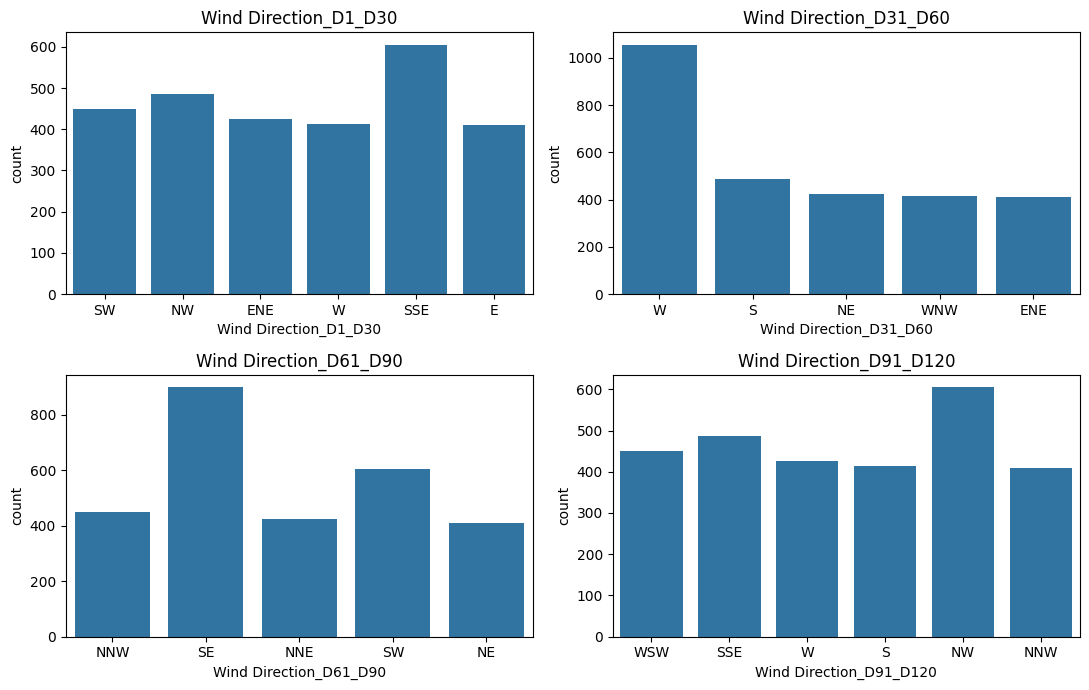

In [67]:
# Distribusi arah angin (kolom kategorikal yang belum divisualisasikan)
wind_cols = [c for c in data.columns if c.startswith('Wind Direction')]
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), wind_cols):
    sns.countplot(data=data, x=c, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

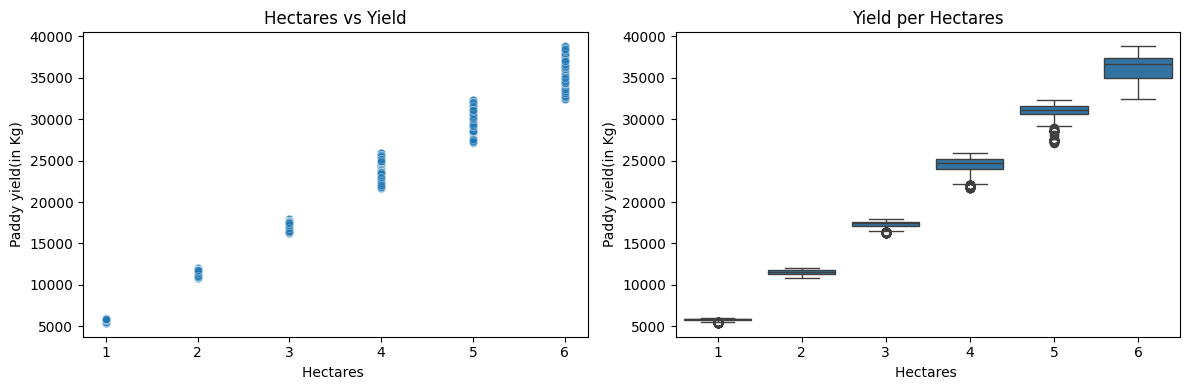

In [68]:
# Hubungan fitur terkuat (Hectares) dengan target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=data, x='Hectares ', y=target, alpha=0.4, ax=ax[0])
sns.boxplot(data=data, x='Hectares ', y=target, ax=ax[1])
ax[0].set_title('Hectares vs Yield'); ax[1].set_title('Yield per Hectares')
plt.tight_layout(); plt.show()

count    2789.0
mean     5990.5
std       283.2
min      5410.0
25%      5836.0
50%      5964.0
75%      6227.0
max      6469.0
dtype: float64


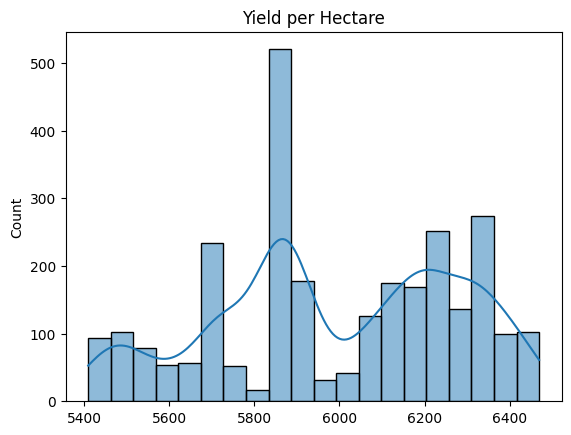

In [69]:
# Yield per hectare: apakah relatif stabil?
yph = data[target] / data['Hectares ']
print(yph.describe().round(1))
sns.histplot(yph, kde=True); plt.title('Yield per Hectare'); plt.show()

In [70]:
# Fitur-fitur yang berkorelasi sangat tinggi dengan Hectares (kandidat redundan)
num = data.select_dtypes('number')
high = num.corr()['Hectares '].drop('Hectares ').abs().sort_values(ascending=False)
high[high > 0.95].to_frame('|corr| dengan Hectares')

                           |corr| dengan Hectares
Micronutrients_70Days                    1.000000
LP_nurseryarea(in Tonnes)                1.000000
Weed28D_thiobencarb                      1.000000
Urea_40Days                              1.000000
Nursery area (Cents)                     1.000000
DAP_20days                               1.000000
Seedrate(in Kg)                          1.000000
LP_Mainfield(in Tonnes)                  1.000000
Pest_60Day(in ml)                        1.000000
Potassh_50Days                           1.000000
Paddy yield(in Kg)                       0.994649
Trash(in bundles)                        0.967012

In [71]:
# Rata-rata yield per kategori (perbedaan antar kategori)
for c in cat_cols + wind_cols:
    print(data.groupby(c)[target].mean().round(0).to_dict())

{'Chinnasalem': 22382.0, 'Cuddalore': 22367.0, 'Kallakurichi': 22251.0, 'Kurinjipadi': 22613.0, 'Panruti': 22329.0, 'Sankarapuram': 22960.0}
{'CO_43': 22541.0, 'delux ponni': 22614.0, 'ponmani': 22411.0}
{'alluvial': 22517.0, 'clay': 22518.0}
{'dry': 22450.0, 'wet': 22601.0}
{'E': 22382.0, 'ENE': 22329.0, 'NW': 22613.0, 'SSE': 22960.0, 'SW': 22367.0, 'W': 22251.0}
{'ENE': 22382.0, 'NE': 22329.0, 'S': 22613.0, 'W': 22707.0, 'WNW': 22251.0}
{'NE': 22382.0, 'NNE': 22329.0, 'NNW': 22367.0, 'SE': 22447.0, 'SW': 22960.0}
{'NNW': 22382.0, 'NW': 22960.0, 'S': 22251.0, 'SSE': 22613.0, 'W': 22329.0, 'WSW': 22367.0}


In [72]:
# Cek outlier dengan metode IQR (TANPA clipping, data tidak diubah)
# selisih = nilai asli - nilai jika di-clip ke batas IQR
num_cols = data.select_dtypes('number').columns
for c in num_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    selisih = data[c] - data[c].clip(lower, upper)
    outlier = selisih[selisih != 0]
    if outlier.empty:
        continue
    print(f'---- {c} ---- ({len(outlier)} outlier, batas IQR: {lower} s/d {upper})')
    for idx, v in outlier.items():
        print(f'baris {idx} : {v}')
    print()

---- Inst Wind Speed_D61_D90(in Knots) ---- (425 outlier, batas IQR: 5.0 s/d 13.0)
baris 2 : -1
baris 8 : -1
baris 14 : -1
baris 20 : -1
baris 26 : -1
baris 32 : -1
baris 38 : -1
baris 44 : -1
baris 50 : -1
baris 56 : -1
baris 62 : -1
baris 68 : -1
baris 74 : -1
baris 80 : -1
baris 86 : -1
baris 92 : -1
baris 98 : -1
baris 104 : -1
baris 110 : -1
baris 116 : -1
baris 122 : -1
baris 128 : -1
baris 134 : -1
baris 140 : -1
baris 146 : -1
baris 158 : -1
baris 159 : -1
baris 160 : -1
baris 161 : -1
baris 162 : -1
baris 202 : -1
baris 208 : -1
baris 214 : -1
baris 220 : -1
baris 226 : -1
baris 232 : -1
baris 238 : -1
baris 244 : -1
baris 250 : -1
baris 256 : -1
baris 262 : -1
baris 268 : -1
baris 274 : -1
baris 280 : -1
baris 286 : -1
baris 292 : -1
baris 298 : -1
baris 304 : -1
baris 310 : -1
baris 316 : -1
baris 322 : -1
baris 328 : -1
baris 334 : -1
baris 340 : -1
baris 346 : -1
baris 358 : -1
baris 359 : -1
baris 360 : -1
baris 361 : -1
baris 362 : -1
baris 402 : -1
baris 408 : -1
baris 